# 00 – Data Loading and Data Types

In this notebook we load the raw dataset, take a first look at its size and structure, check the data types, and fix anything that needs correcting before moving on.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style across all notebooks
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

# Human-readable period labels
PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

In [2]:
df = pd.read_csv("../data/Madrid_Sale.csv")
df.shape

(94815, 41)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94815 entries, 0 to 94814
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ASSETID                        94815 non-null  object 
 1   PERIOD                         94815 non-null  int64  
 2   PRICE                          94815 non-null  float64
 3   UNITPRICE                      94815 non-null  float64
 4   CONSTRUCTEDAREA                94815 non-null  int64  
 5   ROOMNUMBER                     94815 non-null  int64  
 6   BATHNUMBER                     94815 non-null  int64  
 7   HASTERRACE                     94815 non-null  int64  
 8   HASLIFT                        94815 non-null  int64  
 9   HASAIRCONDITIONING             94815 non-null  int64  
 10  AMENITYID                      94815 non-null  int64  
 11  HASPARKINGSPACE                94815 non-null  int64  
 12  ISPARKINGSPACEINCLUDEDINPRICE  94815 non-null 

In [4]:
df.dtypes.value_counts()

int64      29
float64    11
object      1
Name: count, dtype: int64

In [5]:
df.head(3)

,ASSETID,PERIOD,PRICE,UNITPRICE,CONSTRUCTEDAREA,ROOMNUMBER,BATHNUMBER,HASTERRACE,HASLIFT,HASAIRCONDITIONING,AMENITYID,HASPARKINGSPACE,ISPARKINGSPACEINCLUDEDINPRICE,PARKINGSPACEPRICE,HASNORTHORIENTATION,HASSOUTHORIENTATION,HASEASTORIENTATION,HASWESTORIENTATION,HASBOXROOM,HASWARDROBE,HASSWIMMINGPOOL,HASDOORMAN,HASGARDEN,ISDUPLEX,ISSTUDIO,ISINTOPFLOOR,CONSTRUCTIONYEAR,FLOORCLEAN,FLATLOCATIONID,CADCONSTRUCTIONYEAR,CADMAXBUILDINGFLOOR,CADDWELLINGCOUNT,CADASTRALQUALITYID,BUILTTYPEID_1,BUILTTYPEID_2,BUILTTYPEID_3,DISTANCE_TO_CITY_CENTER,DISTANCE_TO_METRO,DISTANCE_TO_CASTELLANA,LONGITUDE,LATITUDE
0,A15019136831406238029,201803,126000.0,2680.851064,47,1,1,0,1,1,3,0,0,1,0,0,0,0,1,1,1,1,1,0,0,0,2005.0,1.0,1.0,2005,7,319,3.0,0,1,0,8.058429,0.872075,6.868677,-3.766933,40.362485
1,A6677225905472065344,201803,235000.0,4351.851852,54,1,1,0,0,0,3,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,NaN,1.0,2.0,1900,5,11,3.0,0,0,1,0.876369,0.116382,1.544125,-3.710725,40.422430
2,A13341979748618524775,201803,373000.0,4973.333333,75,2,1,0,0,1,3,0,0,1,0,1,0,0,1,1,0,0,0,0,0,0,NaN,3.0,1.0,1915,6,26,3.0,0,0,1,0.907479,0.139109,1.608444,-3.711571,40.422190


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PERIOD,94815.0,201808.613289,3.684625,201803.000000,201806.000000,201809.000000,201812.000000,2.018120e+05
PRICE,94815.0,396110.109160,417074.407623,21000.000000,160000.000000,262000.000000,467000.000000,8.133000e+06
UNITPRICE,94815.0,3661.051534,1700.499398,805.309735,2240.000000,3480.000000,4744.623034,9.997561e+03
CONSTRUCTEDAREA,94815.0,101.397163,67.078259,21.000000,62.000000,83.000000,117.000000,9.850000e+02
ROOMNUMBER,94815.0,2.580900,1.244878,0.000000,2.000000,3.000000,3.000000,9.300000e+01
BATHNUMBER,94815.0,1.585456,0.843024,0.000000,1.000000,1.000000,2.000000,2.000000e+01
HASTERRACE,94815.0,0.355260,0.478595,0.000000,0.000000,0.000000,1.000000,1.000000e+00
HASLIFT,94815.0,0.695597,0.460157,0.000000,0.000000,1.000000,1.000000,1.000000e+00
HASAIRCONDITIONING,94815.0,0.448600,0.497354,0.000000,0.000000,0.000000,1.000000,1.000000e+00
AMENITYID,94815.0,2.922660,0.314865,1.000000,3.000000,3.000000,3.000000,3.000000e+00


In [7]:
# Check low-cardinality columns
for col in df.columns:
    n = df[col].nunique(dropna=False)
    if n <= 10:
        print(f"{col} ({n} unique): {sorted(df[col].dropna().unique())}")

PERIOD (4 unique): [201803, 201806, 201809, 201812]
HASTERRACE (2 unique): [0, 1]
HASLIFT (2 unique): [0, 1]
HASAIRCONDITIONING (2 unique): [0, 1]
AMENITYID (3 unique): [1, 2, 3]
HASPARKINGSPACE (2 unique): [0, 1]
ISPARKINGSPACEINCLUDEDINPRICE (2 unique): [0, 1]
HASNORTHORIENTATION (2 unique): [0, 1]
HASSOUTHORIENTATION (2 unique): [0, 1]
HASEASTORIENTATION (2 unique): [0, 1]
HASWESTORIENTATION (2 unique): [0, 1]
HASBOXROOM (2 unique): [0, 1]
HASWARDROBE (2 unique): [0, 1]
HASSWIMMINGPOOL (2 unique): [0, 1]
HASDOORMAN (2 unique): [0, 1]
HASGARDEN (2 unique): [0, 1]
ISDUPLEX (2 unique): [0, 1]
ISSTUDIO (2 unique): [0, 1]
ISINTOPFLOOR (2 unique): [0, 1]
FLATLOCATIONID (3 unique): [1.0, 2.0]
BUILTTYPEID_1 (2 unique): [0, 1]
BUILTTYPEID_2 (2 unique): [0, 1]
BUILTTYPEID_3 (2 unique): [0, 1]


In [8]:
# Check duplicates and leakage
print(f"Unique ASSETIDs: {df['ASSETID'].nunique():,}")
print(f"Total rows:      {len(df):,}")
print(f"Duplicates:      {df['ASSETID'].duplicated().sum():,}")
print(f"\nUNITPRICE == PRICE / CONSTRUCTEDAREA?")
print(f"Max difference: {(df['UNITPRICE'] - df['PRICE'] / df['CONSTRUCTEDAREA']).abs().max():.2e}")

Unique ASSETIDs: 75,804
Total rows:      94,815
Duplicates:      19,011

UNITPRICE == PRICE / CONSTRUCTEDAREA?
Max difference: 6.37e-12


### What we see

The dataset has 94,815 rows and 41 columns. Most of it is already numeric — 29 integer columns, 11 floats, and just one object column (ASSETID, the property identifier). There are 17 binary features (all the HAS and IS columns), all properly coded as 0/1.

A few things stand out right away:

UNITPRICE is exactly PRICE divided by CONSTRUCTEDAREA (the max difference is around 10 to the power of -12). This is target leakage — if we used it as a feature the model would basically already know the answer. We'll need to exclude it.

There are about 19,000 repeated ASSETIDs (94,815 rows but only 75,804 unique properties). They all happen within the same quarter and are mostly the same flat with a slightly different price, so they look like price updates. We'll deal with these in notebook 01.

CONSTRUCTIONYEAR has 59% missing values and some clearly wrong entries (year 1, year 50, year 2291). The cadastral version CADCONSTRUCTIONYEAR is 100% complete, so we have a good alternative.

Q4 2018 has way more listings than the other quarters (around 2 to 3.5 times more), which could be a data collection issue. We should keep PERIOD as a variable so the model can account for this.

### What we do here

We convert PERIOD from integer to string so it's treated as a categorical variable. Everything else (duplicates, missing values, leakage) we leave for notebook 01.

## Fixing data types

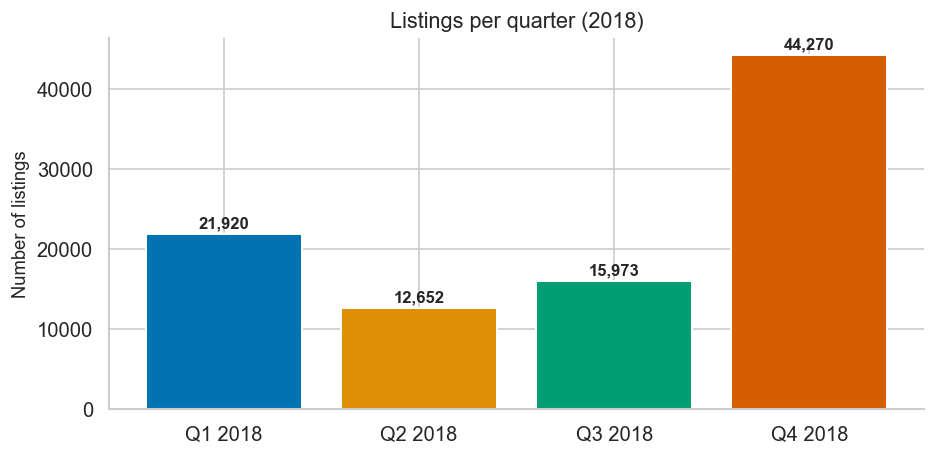

PERIOD dtype: object


In [9]:
df["PERIOD"] = df["PERIOD"].astype(str)

# Show distribution with readable labels
period_counts = df["PERIOD"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(
    [PERIOD_MAP[p] for p in period_counts.index],
    period_counts.values,
    color=sns.color_palette("colorblind", 4),
    edgecolor="white", linewidth=1.2
)
for bar, val in zip(bars, period_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 400,
            f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_ylabel("Number of listings")
ax.set_xlabel("")
ax.set_title("Listings per quarter (2018)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"PERIOD dtype: {df['PERIOD'].dtype}")

In [10]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/listings_00.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 94815 rows × 41 columns


## Conclusion

We loaded the Madrid property sales dataset with 94,815 listings and 41 columns covering the four quarters of 2018. The data is already mostly clean and numeric — no currency symbols to parse, no text-encoded booleans.

The only type fix we made was converting PERIOD to string so it behaves as a categorical variable.

Looking at the describe() output, the typical listing is a flat of about 100 m2 with 2-3 bedrooms, 1-2 bathrooms, on the 2nd or 3rd floor, built around 1965, and located about 4.5 km from the city centre. Prices range from 21,000 to over 8 million EUR, with a median of 262,000 and a mean of 396,000 — the gap between the two tells us the distribution is right-skewed, so we'll probably want a log transformation when modelling.

We spotted three issues to handle in the next notebook: about 19,000 duplicate ASSETIDs (same flat listed multiple times), UNITPRICE as target leakage, and CONSTRUCTIONYEAR with 59% missing values and wrong entries.